# Classification: Predicting Late Delivery Risk
# Phân loại: Dự đoán rủi ro giao hàng trễ

**EN:** This notebook is the classification part of the thesis on the DataCo Smart Supply Chain dataset. Stage 1 (Power BI) showed that more than half of the orders are delivered late. Here we ask: *can we predict, at the moment an order is placed, whether it will be delivered late?* The notebook follows the MIS 451 classification workflow: load data → partition → EDA → transformation → model development → comparison → final model.

**VI:** Notebook này là phần classification của luận văn trên bộ dữ liệu DataCo. Ở Stage 1 (Power BI), hơn một nửa số đơn bị giao trễ. Câu hỏi ở đây là: *có thể dự đoán ngay lúc đặt hàng xem đơn đó có bị giao trễ hay không?* Notebook đi theo quy trình classification của môn MIS 451: đọc dữ liệu → chia dữ liệu → EDA → biến đổi dữ liệu → xây model → so sánh → model cuối.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import logging
logging.basicConfig()
logging.getLogger("SKLEARNEX").setLevel(logging.ERROR)

import warnings
warnings.filterwarnings("ignore")

# Data Preprocessing
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Data Partitioning and Cross-validation
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, GridSearchCV, cross_val_score

# Machine Learning
from sklearn.dummy import DummyClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression

# Metrics
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score
from sklearn.metrics import classification_report, confusion_matrix

np.random.seed(42)

# **1. Load the data**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
file_path = '/content/drive/MyDrive/BUS_450/clean_supply_chain.csv'

In [ ]:
df = pd.read_csv(file_path)

**EN:** Each row is one *order item*. The target is `late_delivery_risk`: **0 = delivered on time, 1 = delivered late**. We only use orders placed until **2017-10-01** (172,127 rows), the same window as the forecasting part, because from October 2017 the dataset changes structure (only 2–3 products per week appear). The check below confirms that all items of one order share the same delivery result (maximum = 1), so the label is really a property of the order.

**VI:** Mỗi dòng là một *mặt hàng trong đơn*. Biến mục tiêu là `late_delivery_risk`: **0 = giao đúng hạn, 1 = giao trễ**. Ta chỉ dùng các đơn đặt đến **2017-10-01** (172,127 dòng), cùng cửa sổ dữ liệu với phần forecast, vì từ tháng 10/2017 dataset thay đổi cấu trúc (mỗi tuần chỉ còn 2–3 sản phẩm). Kiểm tra bên dưới xác nhận mọi mặt hàng trong cùng một đơn có cùng kết quả giao hàng (giá trị lớn nhất = 1), nên nhãn thực chất là thuộc tính của cả đơn.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 48 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   type                         180519 non-null  object 
 1   days_for_shipping_real       180519 non-null  int64  
 2   days_for_shipment_scheduled  180519 non-null  int64  
 3   benefit_per_order            180519 non-null  float64
 4   sales_per_customer           180519 non-null  float64
 5   delivery_status              180519 non-null  object 
 6   late_delivery_risk           180519 non-null  int64  
 7   category_id                  180519 non-null  int64  
 8   category_name                180519 non-null  object 
 9   customer_city                180519 non-null  object 
 10  customer_country             180519 non-null  object 
 11  customer_id                  180519 non-null  int64  
 12  customer_segment             180519 non-null  object 
 13 

In [ ]:
df.head()

,type,days_for_shipping_real,days_for_shipment_scheduled,benefit_per_order,sales_per_customer,delivery_status,late_delivery_risk,category_id,category_name,customer_city,...,product_category_id,product_name,product_price,product_status,shipping_mode,order_date,shipping_date,shipping_delay,order_month,is_late
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,...,73,Smart watch,327.75,0,Standard Class,2018-01-31 22:56:00,2018-02-03 22:56:00,-1,2018-01,False
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,...,73,Smart watch,327.75,0,Standard Class,2018-01-13 12:27:00,2018-01-18 12:27:00,1,2018-01,True
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,...,73,Smart watch,327.75,0,Standard Class,2018-01-13 12:06:00,2018-01-17 12:06:00,0,2018-01,False
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,...,73,Smart watch,327.75,0,Standard Class,2018-01-13 11:45:00,2018-01-16 11:45:00,-1,2018-01,False
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,...,73,Smart watch,327.75,0,Standard Class,2018-01-13 11:24:00,2018-01-15 11:24:00,-2,2018-01,False


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.isnull().sum()

,0
type,0
days_for_shipping_real,0
days_for_shipment_scheduled,0
benefit_per_order,0
sales_per_customer,0
delivery_status,0
late_delivery_risk,0
category_id,0
category_name,0
customer_city,0


In [ ]:
df["order_date"] = pd.to_datetime(df["order_date"])
df["order_date"].dtype

dtype('<M8[ns]')

In [ ]:
data = df[df["order_date"] < "2017-10-02"].copy()
data.shape

(172127, 48)

In [ ]:
data.groupby("order_id")["late_delivery_risk"].nunique().max()

1

In [ ]:
data["late_delivery_risk"].value_counts(normalize=True)

,proportion
late_delivery_risk,
1,0.548101
0,0.451899


**EN:** 54.8% of the orders are late and 45.2% are on time, so the classes are fairly balanced. A trivial rule "always predict late" is already 54.8% accurate. This is the minimum that any useful model has to beat.

**VI:** 54.8% số đơn bị trễ và 45.2% đúng hạn, nên hai lớp khá cân bằng. Một quy tắc đơn giản "luôn đoán là trễ" đã đúng 54.8%. Đây là mức tối thiểu mà một model hữu ích phải vượt qua.

# **2. Data Partitioning**

**EN:** One order can contain several items, and all of them have the same delivery result. If we split the data randomly by row, items of the same order would appear in both the training and the test set. The model would then "see" part of the test orders during training and the test score would look better than it really is. Therefore the data are split **by Order ID**: 80% of the orders for training (137,699 rows) and 20% for testing (34,428 rows). The check below confirms that no order appears in both sets. Cross-validation inside the training set is also grouped by order (`GroupKFold`).

**VI:** Một đơn có thể có nhiều mặt hàng và tất cả đều có cùng kết quả giao hàng. Nếu chia ngẫu nhiên theo dòng, các mặt hàng của cùng một đơn sẽ nằm ở cả tập train lẫn test. Khi đó model đã "nhìn thấy" một phần đơn của tập test lúc học, nên điểm test đẹp hơn thực tế. Vì vậy dữ liệu được chia **theo Order ID**: 80% số đơn để train (137,699 dòng) và 20% để test (34,428 dòng). Kiểm tra bên dưới xác nhận không có đơn nào nằm ở cả hai tập. Cross-validation trong tập train cũng được chia theo đơn (`GroupKFold`).

In [ ]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=99)
train_idx, test_idx = next(gss.split(data, groups=data["order_id"]))

In [ ]:
train = data.iloc[train_idx].reset_index(drop=True)
test = data.iloc[test_idx].reset_index(drop=True)

In [ ]:
train.shape, test.shape

((137699, 48), (34428, 48))

In [ ]:
# No order appears in both sets
len(set(train["order_id"]) & set(test["order_id"]))

0

In [ ]:
train["late_delivery_risk"].value_counts(normalize=True)

,proportion
late_delivery_risk,
1,0.548101
0,0.451899


In [ ]:
print(train["order_date"].dtype, "|", test["order_date"].dtype)
print(data["order_date"].min(), "→", data["order_date"].max())
data.shape, train.shape, test.shape

datetime64[ns] | datetime64[ns]
2015-01-01 00:00:00 → 2017-10-01 23:49:00


((172127, 48), (137699, 48), (34428, 48))

# **3. Exploratory Data Analysis**

**EN:** The model is meant to estimate the risk of a late delivery **when the order is placed**, so we only use information that is known at that moment:

- **Used:** shipping mode, payment type, customer segment, market, order region, product category, department, scheduled shipping days, quantity, product price, discount, discount rate, order month.
- **Not used (data leakage):** `days_for_shipping_real`, `shipping_delay`, `shipping_date`, `delivery_status`, `is_late`, `order_status`. These columns describe what happened during or after the delivery. With them the model would only "discover" that an order is late because the data already say it is late.

**VI:** Model dùng để ước lượng rủi ro giao trễ **ngay lúc đặt hàng**, nên chỉ dùng thông tin đã biết ở thời điểm đó:

- **Dùng:** shipping mode, loại thanh toán, customer segment, market, vùng đặt hàng, nhóm sản phẩm, department, số ngày giao dự kiến, số lượng, giá sản phẩm, discount, tỉ lệ discount, tháng đặt hàng.
- **Không dùng (rò rỉ dữ liệu):** `days_for_shipping_real`, `shipping_delay`, `shipping_date`, `delivery_status`, `is_late`, `order_status`. Các cột này mô tả những gì xảy ra trong hoặc sau khi giao hàng. Nếu dùng, model chỉ "phát hiện" đơn trễ vì dữ liệu đã cho biết đơn đó trễ.

In [ ]:
# Variables known when the order is placed (no information from the delivery itself)
cat_cols = ["shipping_mode", "type", "customer_segment", "market",
            "order_region", "category_name", "department_name"]
num_cols = ["days_for_shipment_scheduled", "order_item_quantity", "order_item_product_price",
            "order_item_discount", "order_item_discount_rate", "order_month_num"]

train["order_month_num"] = train["order_date"].dt.month
test["order_month_num"] = test["order_date"].dt.month

target = "late_delivery_risk"

In [ ]:
train[cat_cols + num_cols].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 137699 entries, 0 to 137698
Data columns (total 13 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   shipping_mode                137699 non-null  object 
 1   type                         137699 non-null  object 
 2   customer_segment             137699 non-null  object 
 3   market                       137699 non-null  object 
 4   order_region                 137699 non-null  object 
 5   category_name                137699 non-null  object 
 6   department_name              137699 non-null  object 
 7   days_for_shipment_scheduled  137699 non-null  int64  
 8   order_item_quantity          137699 non-null  int64  
 9   order_item_product_price     137699 non-null  float64
 10  order_item_discount          137699 non-null  float64
 11  order_item_discount_rate     137699 non-null  float64
 12  order_month_num              137699 non-null  int32  
dtyp

In [ ]:
train[cat_cols + num_cols].isnull().sum()

,0
shipping_mode,0
type,0
customer_segment,0
market,0
order_region,0
category_name,0
department_name,0
days_for_shipment_scheduled,0
order_item_quantity,0
order_item_product_price,0


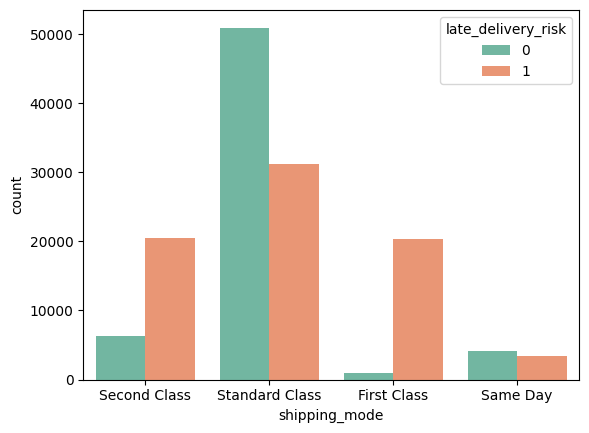

In [ ]:
# Late rate by shipping mode (same style as the classification notebook)
sns.countplot(train, x="shipping_mode", hue=target, palette="Set2")
plt.show()

In [ ]:
# Late rate (%) by shipping mode
(pd.crosstab(train["shipping_mode"], train[target], normalize="index") * 100).round(1)

late_delivery_risk,0,1
shipping_mode,,
First Class,4.5,95.5
Same Day,54.6,45.4
Second Class,23.3,76.7
Standard Class,62.0,38.0


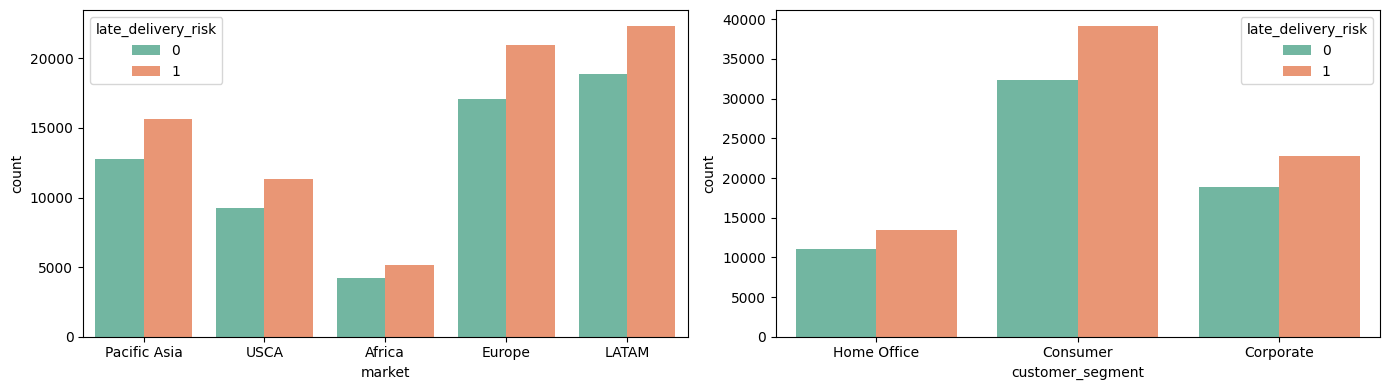

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.countplot(train, x="market", hue=target, palette="Set2", ax=axes[0])
sns.countplot(train, x="customer_segment", hue=target, palette="Set2", ax=axes[1])
plt.tight_layout()
plt.show()

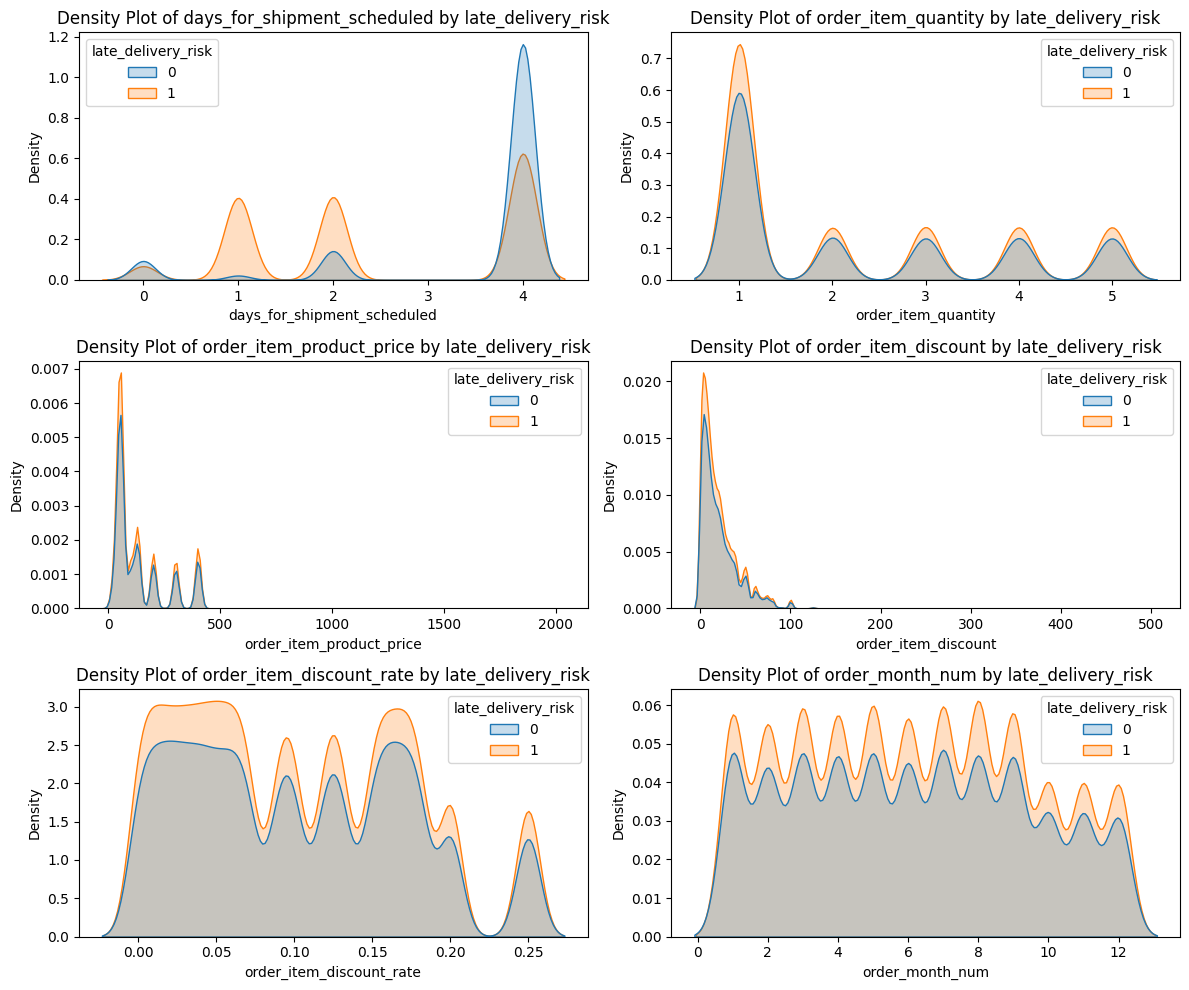

In [ ]:
plt.figure(figsize=(12, 10))
for i, col in enumerate(num_cols, 1):
    plt.subplot(3, 2, i)
    sns.kdeplot(data=train, x=col, hue=target, fill=True)
    plt.title(f"Density Plot of {col} by {target}", fontsize=12)
plt.tight_layout()
plt.show()

In [ ]:
# Late rate (%) by scheduled shipping days
(pd.crosstab(train["days_for_shipment_scheduled"], train[target], normalize="index") * 100).round(1)

late_delivery_risk,0,1
days_for_shipment_scheduled,,
0,54.6,45.4
1,4.5,95.5
2,23.3,76.7
4,62.0,38.0


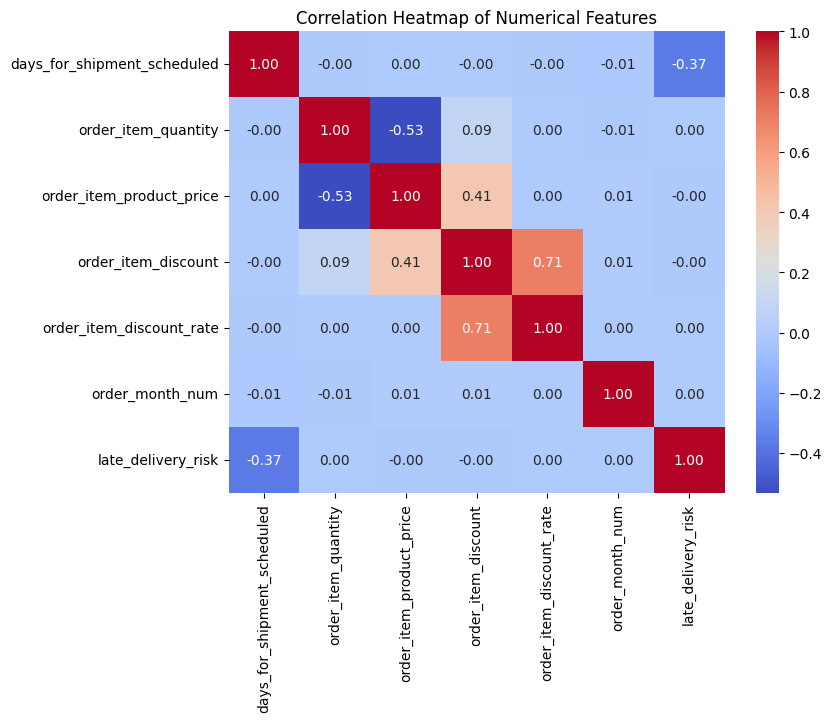

In [ ]:
plt.figure(figsize=(8, 6))
sns.heatmap(train[num_cols + [target]].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap of Numerical Features")
plt.show()

**EN – Findings:**
- **Shipping mode is the strongest signal.** In the training set the late rate is 95.5% for First Class, 76.7% for Second Class, 45.4% for Same Day and 38.0% for Standard Class.
- **Scheduled shipping days gives exactly the same rates** (1 day = 95.5%, 2 days = 76.7%, 0 days = 45.4%, 4 days = 38.0%). So it carries the same information as shipping mode: each mode has one promised delivery time.
- The faster (and more expensive) modes are late more often. A possible explanation is that the promised delivery time of these modes is too tight; this should be discussed together with the Stage 1 results.
- The other variables are much less informative. In every market and customer segment late orders are the larger group, with similar proportions. For quantity, product price and discount the density curves of the two classes almost overlap.

**VI – Nhận xét:**
- **Shipping mode là tín hiệu mạnh nhất.** Trong tập train, tỉ lệ trễ là 95.5% với First Class, 76.7% với Second Class, 45.4% với Same Day và 38.0% với Standard Class.
- **Số ngày giao dự kiến cho đúng cùng các tỉ lệ đó** (1 ngày = 95.5%, 2 ngày = 76.7%, 0 ngày = 45.4%, 4 ngày = 38.0%). Nghĩa là nó mang cùng thông tin với shipping mode: mỗi mode có một thời gian giao đã hứa.
- Các mode nhanh hơn (và đắt hơn) lại trễ nhiều hơn. Một lời giải thích có thể là thời gian giao hứa cho các mode này quá chặt; nên đối chiếu với kết quả Stage 1.
- Các biến còn lại ít thông tin hơn nhiều. Ở mọi market và customer segment, đơn trễ đều chiếm nhiều hơn với tỉ lệ tương tự nhau. Với số lượng, giá sản phẩm và discount, đường mật độ của hai lớp gần như chồng lên nhau.

# **4. Data Transformation**

**EN:** Models need numbers, so the 7 categorical variables are converted by **one-hot encoding** (each category becomes a 0/1 column, which gives 83 columns in total together with the 6 numerical variables). The numerical variables are **standardised** so that they have a comparable scale; this matters for KNN, SVM, Logistic Regression and the neural network. The encoder and the scaler are fitted on the **training set only** and then applied to the test set, so that no information from the test set leaks into training.

**VI:** Model cần dữ liệu dạng số, nên 7 biến phân loại được chuyển bằng **one-hot encoding** (mỗi nhóm thành một cột 0/1, cùng với 6 biến số, tổng cộng 83 cột). Các biến số được **chuẩn hóa** để có cùng thang đo; điều này quan trọng với KNN, SVM, Logistic Regression và mạng nơ-ron. Encoder và scaler chỉ được fit trên **tập train** rồi mới áp dụng cho tập test, để thông tin của tập test không lọt vào quá trình học.

In [ ]:
one_hot_encoder = OneHotEncoder(sparse_output=False, handle_unknown="ignore")

transformed = one_hot_encoder.fit_transform(train[cat_cols])       # fit on train only
new_col_names = one_hot_encoder.get_feature_names_out(cat_cols)

Xtrain = pd.concat([train[num_cols], pd.DataFrame(transformed, columns=new_col_names)], axis=1)
Xtest = pd.concat([test[num_cols],
                   pd.DataFrame(one_hot_encoder.transform(test[cat_cols]), columns=new_col_names)], axis=1)

ytrain = train[target].copy()
ytest = test[target].copy()

Xtrain.shape, Xtest.shape

((137699, 83), (34428, 83))

In [ ]:
feature_names = Xtrain.columns
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(Xtrain)
X_test_scaled = scaler.transform(Xtest)

Xtrain, Xtest = X_train_scaled, X_test_scaled
groups_train = train["order_id"]

# **5. Model Development**

**EN:** Four models from the course are compared: KNN, SVM, Logistic Regression and a neural network (ANN). Metrics:

- **Accuracy:** share of correct predictions.
- **F1 (macro):** average F1 of the two classes; our main metric because it treats late and on-time orders equally.
- **Precision (Late):** when the model says "late", how often it is right.
- **Recall (Late):** of all orders that are really late, how many the model finds.
- **ROC-AUC:** how well the model ranks late orders above on-time orders (0.5 = guessing, 1 = perfect).

Models are **chosen** with grouped cross-validation on the training set (F1 macro) and **confirmed once** on the test set. KNN and SVM are slow on 137 thousand rows, so they are tuned and trained on a random sample of 8,000 orders (about 22 thousand rows).

**VI:** So sánh bốn model trong môn học: KNN, SVM, Logistic Regression và mạng nơ-ron (ANN). Các chỉ số:

- **Accuracy:** tỉ lệ dự đoán đúng.
- **F1 (macro):** trung bình F1 của hai lớp; là chỉ số chính vì xem đơn trễ và đơn đúng hạn ngang nhau.
- **Precision (Late):** khi model nói "trễ" thì đúng bao nhiêu phần.
- **Recall (Late):** trong các đơn thật sự trễ, model tìm ra được bao nhiêu.
- **ROC-AUC:** khả năng xếp đơn trễ cao hơn đơn đúng hạn (0.5 = đoán mò, 1 = hoàn hảo).

Model được **chọn** bằng cross-validation theo nhóm đơn trên tập train (F1 macro) và **xác nhận một lần** trên tập test. KNN và SVM chạy chậm trên 137 nghìn dòng, nên được tune và huấn luyện trên một mẫu ngẫu nhiên gồm 8,000 đơn (khoảng 22 nghìn dòng).

In [ ]:
results_clf = {}

def score_classifier(name, y_true, y_pred, y_score):
    results_clf[name] = {
        "Accuracy": accuracy_score(y_true, y_pred),
        "F1 (macro)": f1_score(y_true, y_pred, average="macro"),
        "Precision (Late)": precision_score(y_true, y_pred),
        "Recall (Late)": recall_score(y_true, y_pred),
        "ROC-AUC": roc_auc_score(y_true, y_score)
    }

gkf = GroupKFold(n_splits=5)

In [ ]:
# Random sample of orders for KNN and SVM (they are slow on 137 thousand rows)
rng = np.random.RandomState(99)
sample_orders = rng.choice(train["order_id"].unique(), size=8000, replace=False)
mask = train["order_id"].isin(sample_orders).values

Xs, ys, gs = Xtrain[mask], ytrain[mask], groups_train[mask]
Xs.shape

(23913, 83)

**5.0 Baseline**

**EN:** Two baselines give a reference point. (1) *Majority class*: always predict "late" (accuracy 54.8%, F1 macro 0.354). (2) *Shipping mode only*: a logistic regression that uses nothing but shipping mode. It tests whether the other variables add anything beyond what shipping mode already explains. A model is worth keeping only if it clearly beats both.

**VI:** Hai baseline làm mốc so sánh. (1) *Majority class*: luôn đoán "trễ" (accuracy 54.8%, F1 macro 0.354). (2) *Chỉ dùng shipping mode*: một logistic regression chỉ có shipping mode. Baseline này kiểm tra xem các biến còn lại có thêm được gì so với những gì shipping mode đã giải thích. Một model chỉ đáng giữ nếu thắng rõ cả hai baseline.

In [ ]:
dummy = DummyClassifier(strategy="most_frequent").fit(Xtrain, ytrain)
score_classifier("Baseline (majority class)", ytest, dummy.predict(Xtest), np.full(len(ytest), 0.5))

In [ ]:
sm_cols = [i for i, c in enumerate(feature_names) if c.startswith("shipping_mode_")]
lr_base = LogisticRegression().fit(Xtrain[:, sm_cols], ytrain)
score_classifier("Baseline 2 (shipping mode only)", ytest, lr_base.predict(Xtest[:, sm_cols]),
                 lr_base.predict_proba(Xtest[:, sm_cols])[:, 1])

**5.1 KNN**

**EN – KNN:** predicts an order by looking at the K most similar orders in the training data and taking the majority result. K (5, 11 or 21) is chosen by grouped cross-validation.

**EN – SVM:** finds a boundary that separates late from on-time orders with the largest margin.

Both models are trained on the random sample of 8,000 orders (see above).

**VI – KNN:** dự đoán một đơn bằng cách xem K đơn giống nó nhất trong dữ liệu train và lấy kết quả chiếm đa số. K (5, 11 hoặc 21) được chọn bằng cross-validation theo nhóm đơn.

**VI – SVM:** tìm một đường biên tách đơn trễ và đơn đúng hạn với khoảng cách lề lớn nhất.

Cả hai model đều được huấn luyện trên mẫu ngẫu nhiên 8,000 đơn (xem ở trên).

In [ ]:
param_grid = {"n_neighbors": [5, 11, 21]}
grid = GridSearchCV(KNeighborsClassifier(), param_grid, cv=gkf, scoring="f1_macro")
grid.fit(Xs, ys, groups=gs)
print("Best params:", grid.best_params_)

Best params: {'n_neighbors': 21}


In [ ]:
knn = KNeighborsClassifier(n_neighbors=grid.best_params_["n_neighbors"])
knn_fscore = cross_val_score(knn, Xs, ys, scoring="f1_macro", cv=gkf, groups=gs)
knn_fscore, knn_fscore.mean()

(array([0.64722532, 0.65561474, 0.65779034, 0.65213276, 0.6471754 ]),
 np.float64(0.651987712029721))

In [ ]:
knn.fit(Xs, ys)                     # fitted on the sample only
score_classifier("KNN", ytest, knn.predict(Xtest), knn.predict_proba(Xtest)[:, 1])

**5.2 SVM**

In [ ]:
svc = SVC()
svc_fscore = cross_val_score(svc, Xs, ys, scoring="f1_macro", cv=gkf, groups=gs)
svc_fscore, svc_fscore.mean()

(array([0.68526542, 0.68773779, 0.68724181, 0.68932984, 0.67191877]),
 np.float64(0.6842987261329471))

In [ ]:
svc.fit(Xs, ys)                     # fitted on the sample only
score_classifier("SVM", ytest, svc.predict(Xtest), svc.decision_function(Xtest))

**5.3 Logistic Regression**

**EN – Logistic Regression:** a simple model that gives each variable a weight and turns the weighted sum into a probability of being late. Its weights can be read directly, which makes it easy to explain.

**EN – ANN:** a small neural network (two hidden layers with 64 and 32 neurons) trained to output the probability of being late. `EarlyStopping` stops the training when the validation loss no longer improves, to avoid overfitting.

**VI – Logistic Regression:** model đơn giản, gán một trọng số cho mỗi biến rồi đổi tổng có trọng số thành xác suất bị trễ. Có thể đọc trực tiếp các trọng số nên dễ giải thích.

**VI – ANN:** mạng nơ-ron nhỏ (hai lớp ẩn với 64 và 32 nơ-ron) được huấn luyện để cho ra xác suất bị trễ. `EarlyStopping` dừng huấn luyện khi validation loss không còn cải thiện, để tránh overfitting.

In [ ]:
lr = LogisticRegression(max_iter=1000)
lr_fscore = cross_val_score(lr, Xtrain, ytrain, scoring="f1_macro", cv=gkf, groups=groups_train)
lr_fscore, lr_fscore.mean()

(array([0.6958205 , 0.69435402, 0.69585334, 0.68883831, 0.68521331]),
 np.float64(0.6920158951837312))

In [ ]:
lr.fit(Xtrain, ytrain)
score_classifier("Logistic Regression", ytest, lr.predict(Xtest), lr.predict_proba(Xtest)[:, 1])

**5.4 Deep Learning (ANN)**

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

tf.random.set_seed(42)

ann = Sequential([
    Input(shape=(Xtrain.shape[1],)),
    Dense(64, activation="relu"),
    Dropout(0.3),
    Dense(32, activation="relu"),
    Dropout(0.2),
    Dense(1, activation="sigmoid")
])

ann.compile(optimizer=Adam(0.001), loss="binary_crossentropy", metrics=["accuracy"])
early_stop = EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)

history = ann.fit(Xtrain, ytrain.astype(int).values,
                  epochs=30, batch_size=64, validation_split=0.2,
                  callbacks=[early_stop], verbose=0)

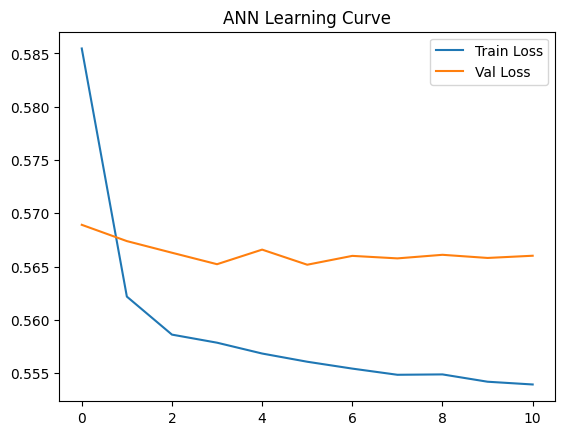

In [ ]:
plt.plot(history.history["loss"], label="Train Loss")
plt.plot(history.history["val_loss"], label="Val Loss")
plt.legend()
plt.title("ANN Learning Curve")
plt.show()

In [ ]:
ann_prob = ann.predict(Xtest, verbose=0).flatten()
score_classifier("ANN", ytest, (ann_prob > 0.5).astype(int), ann_prob)

# **Model Comparison**

In [ ]:
comparison_clf = pd.DataFrame(results_clf).T.round(4).sort_values("F1 (macro)", ascending=False)
comparison_clf

,Accuracy,F1 (macro),Precision (Late),Recall (Late),ROC-AUC
ANN,0.6920,0.6895,0.8301,0.5507,0.7376
Baseline 2 (shipping mode only),0.6924,0.6892,0.8430,0.5392,0.7248
Logistic Regression,0.6919,0.6889,0.8390,0.5419,0.7354
SVM,0.6821,0.6811,0.7911,0.5708,0.7231
KNN,0.6509,0.6508,0.7165,0.6007,0.6974
Baseline (majority class),0.5481,0.3540,0.5481,1.0000,0.5000


In [ ]:
cv_shipping_only = cross_val_score(LogisticRegression(), Xtrain[:, sm_cols], ytrain,
                                   scoring="f1_macro", cv=gkf, groups=groups_train)

cv_table = pd.DataFrame({
    "CV F1 (macro) mean": [knn_fscore.mean(), svc_fscore.mean(), lr_fscore.mean(), cv_shipping_only.mean()],
    "CV F1 (macro) std":  [knn_fscore.std(),  svc_fscore.std(),  lr_fscore.std(),  cv_shipping_only.std()]
}, index=["KNN", "SVM", "Logistic Regression", "LR - shipping mode only"]).round(4)
cv_table.sort_values("CV F1 (macro) mean", ascending=False)

,CV F1 (macro) mean,CV F1 (macro) std
LR - shipping mode only,0.6928,0.0041
Logistic Regression,0.6920,0.0043
SVM,0.6843,0.0063
KNN,0.6520,0.0043


**EN – Discussion:**
- Every model is far better than the majority baseline (F1 macro 0.354).
- On the test set the three best results are almost identical: ANN 0.6895, the shipping-mode-only baseline 0.6892 and Logistic Regression 0.6889. The difference (less than 0.001) is too small to say that one is better. SVM (0.6811) is a little lower and KNN (0.6508) is the lowest, probably because it works on 83 columns and was trained on a sample.
- Cross-validation on the training set agrees: shipping mode only 0.6928, Logistic Regression 0.6920, SVM 0.6843, KNN 0.6520. The gap between the first two is smaller than the variation between folds (see the `std` column), so they are tied.
- **Main finding:** a model that uses only shipping mode is as good as the complex models. The other variables add almost nothing, which is consistent with the EDA.
- **Decision:** we choose **Logistic Regression** as the final model. It ties in performance with the ANN and the baseline, uses all variables, has a slightly higher ROC-AUC than the shipping-mode-only baseline, and can be explained through its coefficients. The small advantage of the ANN is not meaningful, and its result changes slightly from run to run.

**VI – Thảo luận:**
- Mọi model đều tốt hơn nhiều so với baseline majority (F1 macro 0.354).
- Trên tập test, ba kết quả tốt nhất gần như giống nhau: ANN 0.6895, baseline chỉ dùng shipping mode 0.6892 và Logistic Regression 0.6889. Chênh lệch (dưới 0.001) quá nhỏ để nói model nào tốt hơn. SVM (0.6811) thấp hơn một chút và KNN (0.6508) thấp nhất, có thể vì KNN làm việc trên 83 cột và chỉ được huấn luyện trên mẫu.
- Cross-validation trên tập train cho kết quả tương tự: chỉ shipping mode 0.6928, Logistic Regression 0.6920, SVM 0.6843, KNN 0.6520. Khoảng cách giữa hai dòng đầu nhỏ hơn mức dao động giữa các fold (xem cột `std`), nên hai model này hòa.
- **Phát hiện chính:** model chỉ dùng shipping mode tốt ngang các model phức tạp. Các biến còn lại gần như không thêm được gì, khớp với kết quả EDA.
- **Quyết định:** chọn **Logistic Regression** làm model cuối. Nó hòa về hiệu quả với ANN và baseline, dùng đủ các biến, có ROC-AUC cao hơn một chút so với baseline chỉ dùng shipping mode, và giải thích được qua các hệ số. Lợi thế nhỏ của ANN không có ý nghĩa, và kết quả của ANN thay đổi nhẹ giữa các lần chạy.

# **Final Model**

In [ ]:
final_model = lr
y_pred_final = final_model.predict(Xtest)

print(classification_report(ytest, y_pred_final, digits=4))
print("Confusion Matrix:")
print(confusion_matrix(ytest, y_pred_final))

              precision    recall  f1-score   support

           0     0.6113    0.8738    0.7194     15558
           1     0.8390    0.5419    0.6585     18870

    accuracy                         0.6919     34428
   macro avg     0.7251    0.7079    0.6889     34428
weighted avg     0.7361    0.6919    0.6860     34428

Confusion Matrix:
[[13595  1963]
 [ 8644 10226]]


**EN – Reading the result on the test set (34,428 rows):** accuracy 0.692 and F1 macro 0.689.
- For **on-time orders** the model recognises them well: 13,595 of 15,558 are correct (recall 0.87).
- For **late orders** the model is reliable when it raises an alarm: when it says "late", it is right 84% of the time (precision 0.84). But it finds only 54% of the late orders (recall 0.54): 10,226 are found and **8,644 are missed**. It gives 1,963 false alarms.
- In short: the model is a *conservative* alarm. It is useful to flag high-risk orders, but it cannot be used to catch all late orders. A probability threshold lower than 0.5 would find more late orders but give more false alarms (not tested here).

**VI – Đọc kết quả trên tập test (34,428 dòng):** accuracy 0.692 và F1 macro 0.689.
- Với **đơn đúng hạn**, model nhận ra khá tốt: đúng 13,595 trên 15,558 đơn (recall 0.87).
- Với **đơn trễ**, model đáng tin khi đã báo động: khi nói "trễ" thì đúng 84% (precision 0.84). Nhưng chỉ tìm được 54% số đơn trễ (recall 0.54): tìm đúng 10,226 đơn và **bỏ sót 8,644 đơn**. Có 1,963 báo động nhầm.
- Tóm lại: model là một bộ báo động *thận trọng*. Nó hữu ích để đánh dấu các đơn rủi ro cao, nhưng không thể dùng để bắt hết đơn trễ. Dùng ngưỡng xác suất thấp hơn 0.5 sẽ tìm được nhiều đơn trễ hơn nhưng tăng báo động nhầm (chưa thử ở đây).

In [ ]:
coef = pd.Series(lr.coef_[0], index=feature_names).sort_values(key=abs, ascending=False)
coef.head(10)

,0
shipping_mode_First Class,0.688716
shipping_mode_Standard Class,-0.428332
shipping_mode_Same Day,-0.369115
days_for_shipment_scheduled,-0.364493
type_TRANSFER,-0.141914
shipping_mode_Second Class,0.113649
type_PAYMENT,0.063272
type_DEBIT,0.052046
type_CASH,0.036806
order_region_Canada,-0.033227


**EN:** These are the 10 largest coefficients of the Logistic Regression. A **positive** coefficient raises the predicted probability of a late delivery, a **negative** one lowers it. Because the variables were standardised, the sizes of the coefficients can be compared with each other.
- The four largest coefficients all belong to shipping mode and scheduled shipping days (between 0.36 and 0.69 in absolute value): First Class raises the risk (+0.69), while Standard Class (-0.43), Same Day (-0.37) and a longer scheduled time (-0.36) lower it.
- All the remaining coefficients are 0.14 or smaller in absolute value (for example payment type TRANSFER -0.14, shipping mode Second Class +0.11, other payment types and the Canada region below 0.07). This confirms that the model relies almost entirely on shipping mode.
- Shipping mode and scheduled days carry the same information, so their coefficients should be read together, not one by one (the negative sign of scheduled days should not be interpreted on its own).

**VI:** Đây là 10 hệ số lớn nhất của Logistic Regression. Hệ số **dương** làm tăng xác suất dự đoán giao trễ, hệ số **âm** làm giảm. Vì các biến đã được chuẩn hóa nên có thể so sánh độ lớn của các hệ số với nhau.
- Bốn hệ số lớn nhất đều thuộc về shipping mode và số ngày giao dự kiến (độ lớn từ 0.36 đến 0.69): First Class làm tăng rủi ro (+0.69), trong khi Standard Class (-0.43), Same Day (-0.37) và thời gian giao dự kiến dài hơn (-0.36) làm giảm.
- Các hệ số còn lại đều có độ lớn từ 0.14 trở xuống (ví dụ loại thanh toán TRANSFER -0.14, shipping mode Second Class +0.11, các loại thanh toán khác và vùng Canada dưới 0.07). Điều này xác nhận model gần như chỉ dựa vào shipping mode.
- Shipping mode và số ngày giao dự kiến mang cùng một thông tin, nên cần đọc các hệ số của chúng cùng nhau, không đọc riêng từng cái (không nên diễn giải dấu âm của số ngày giao dự kiến một mình).

# Conclusion and Limitations / Kết luận và hạn chế

**EN – Conclusion:** The risk of a late delivery can be predicted moderately well from information known when the order is placed (F1 macro about 0.69, ROC-AUC about 0.73, much better than the 0.354 of the majority baseline). However, almost all the predictive power comes from **shipping mode**, which is the same as the promised delivery time. More complex models (SVM, ANN) do not improve the result. For the business this means that reviewing the **promised delivery times** of the First Class and Second Class modes is likely to matter more than building a more complex model.

**VI – Kết luận:** Rủi ro giao trễ có thể dự đoán ở mức khá từ các thông tin biết lúc đặt hàng (F1 macro khoảng 0.69, ROC-AUC khoảng 0.73, tốt hơn nhiều so với 0.354 của baseline majority). Tuy nhiên gần như toàn bộ sức dự đoán đến từ **shipping mode**, cũng chính là thời gian giao đã hứa. Các model phức tạp hơn (SVM, ANN) không cải thiện kết quả. Với doanh nghiệp, điều này cho thấy việc xem lại **thời gian giao hứa** của First Class và Second Class có thể quan trọng hơn việc xây model phức tạp hơn.

**EN – Limitations:**
- KNN and SVM were tuned and trained on a random sample of 8,000 orders, not on the whole training set.
- SVM, Logistic Regression and the ANN were not tuned (default or simple settings).
- The ANN has no cross-validation score and its result varies slightly between runs.
- Only one train/test split was used.
- The model uses information known at order time. It estimates risk; it does not explain the causes of lateness.
- Orders after 2017-10-01 are excluded because the dataset changes structure.

**VI – Hạn chế:**
- KNN và SVM được tune và huấn luyện trên mẫu ngẫu nhiên 8,000 đơn, không dùng toàn bộ tập train.
- SVM, Logistic Regression và ANN không được tune (dùng cấu hình mặc định hoặc đơn giản).
- ANN không có điểm cross-validation và kết quả thay đổi nhẹ giữa các lần chạy.
- Chỉ dùng một lần chia train/test.
- Model dùng thông tin biết lúc đặt hàng. Nó ước lượng rủi ro, không giải thích nguyên nhân gây trễ.
- Các đơn sau 2017-10-01 bị loại vì dataset thay đổi cấu trúc.